# EngineHealth - FD001 walkthrough notebook
**INT395 Supervised Learning · CA1 · SIH26054 "Aero Piston Engine Fault Prediction"**

This notebook explains the whole workflow step by step on the **FD001** subset (the simplest one) using the same
code that powers the website (`src/` folder). Run the cells from top to bottom.

> **Important:** NASA C-MAPSS simulates **turbofan** engines. It is used here as an *open proxy* for piston-engine telemetry. We never claim it is real piston-engine data.

**What is RUL?** Remaining Useful Life = how many more operating cycles an engine can run before it fails.
We predict it with *regression* (a number) and also build a *classifier* ("will it fail within 30 cycles? yes/no").

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import config as cfg
from src import data_loader as dl
from src.preprocessing import Preprocessor, data_quality_report, pca_analysis
from src.predict import make_features
from src.evaluate import regression_metrics, nasa_score
sns.set_theme(style="whitegrid")
SUBSET = "FD001"
print("Project folder:", ROOT)

Project folder: /home/claude/EngineHealth


## 1. Load the data (Unit I)
Each row = one flight cycle of one engine: `unit`, `cycle`, 3 operating settings `op1-3`, 21 sensors `s1-s21`. The raw files have **no header**, so we name the columns ourselves (`config.py`). The raw files are never modified.

In [2]:
train = dl.add_train_rul(dl.load_train(SUBSET))     # adds the RUL column
test_raw = dl.load_test(SUBSET)
truth = dl.load_rul_truth(SUBSET)                   # official RUL after the last test cycle
print("train", train.shape, "| test", test_raw.shape, "| true RUL values", len(truth))
train.head()

train (20631, 27) | test (13096, 26) | true RUL values 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 2. Data quality: missing values, duplicates, constant columns, outliers (Unit I)

In [3]:
q = data_quality_report(train)
print(json.dumps({k: v for k, v in q.items() if k != "outliers_3xIQR_per_column"}, indent=2))
print("Columns with extreme values (>3xIQR):", q["outliers_3xIQR_per_column"])

{
  "rows": 20631,
  "engines": 100,
  "columns": 27,
  "missing_values": 0,
  "duplicate_rows": 0,
  "constant_columns": [
    "op3",
    "s1",
    "s5",
    "s10",
    "s16",
    "s18",
    "s19"
  ],
  "engine_life_min": 128,
  "engine_life_mean": 206.3,
  "engine_life_max": 362,
  "cycles_are_consecutive": true
}
Columns with extreme values (>3xIQR): {'s6': 406, 's8': 6, 's9': 805, 's13': 5, 's14': 689}


**Reading this:** no missing values and no duplicates, so nothing needs imputing. Some columns are **constant** (they never change) - they carry no information and are removed later.
Extreme values are kept: in degradation data, the unusual values near failure *are* the signal.

## 3. Explore the sensors (Unit I - Pandas / Matplotlib / Seaborn)

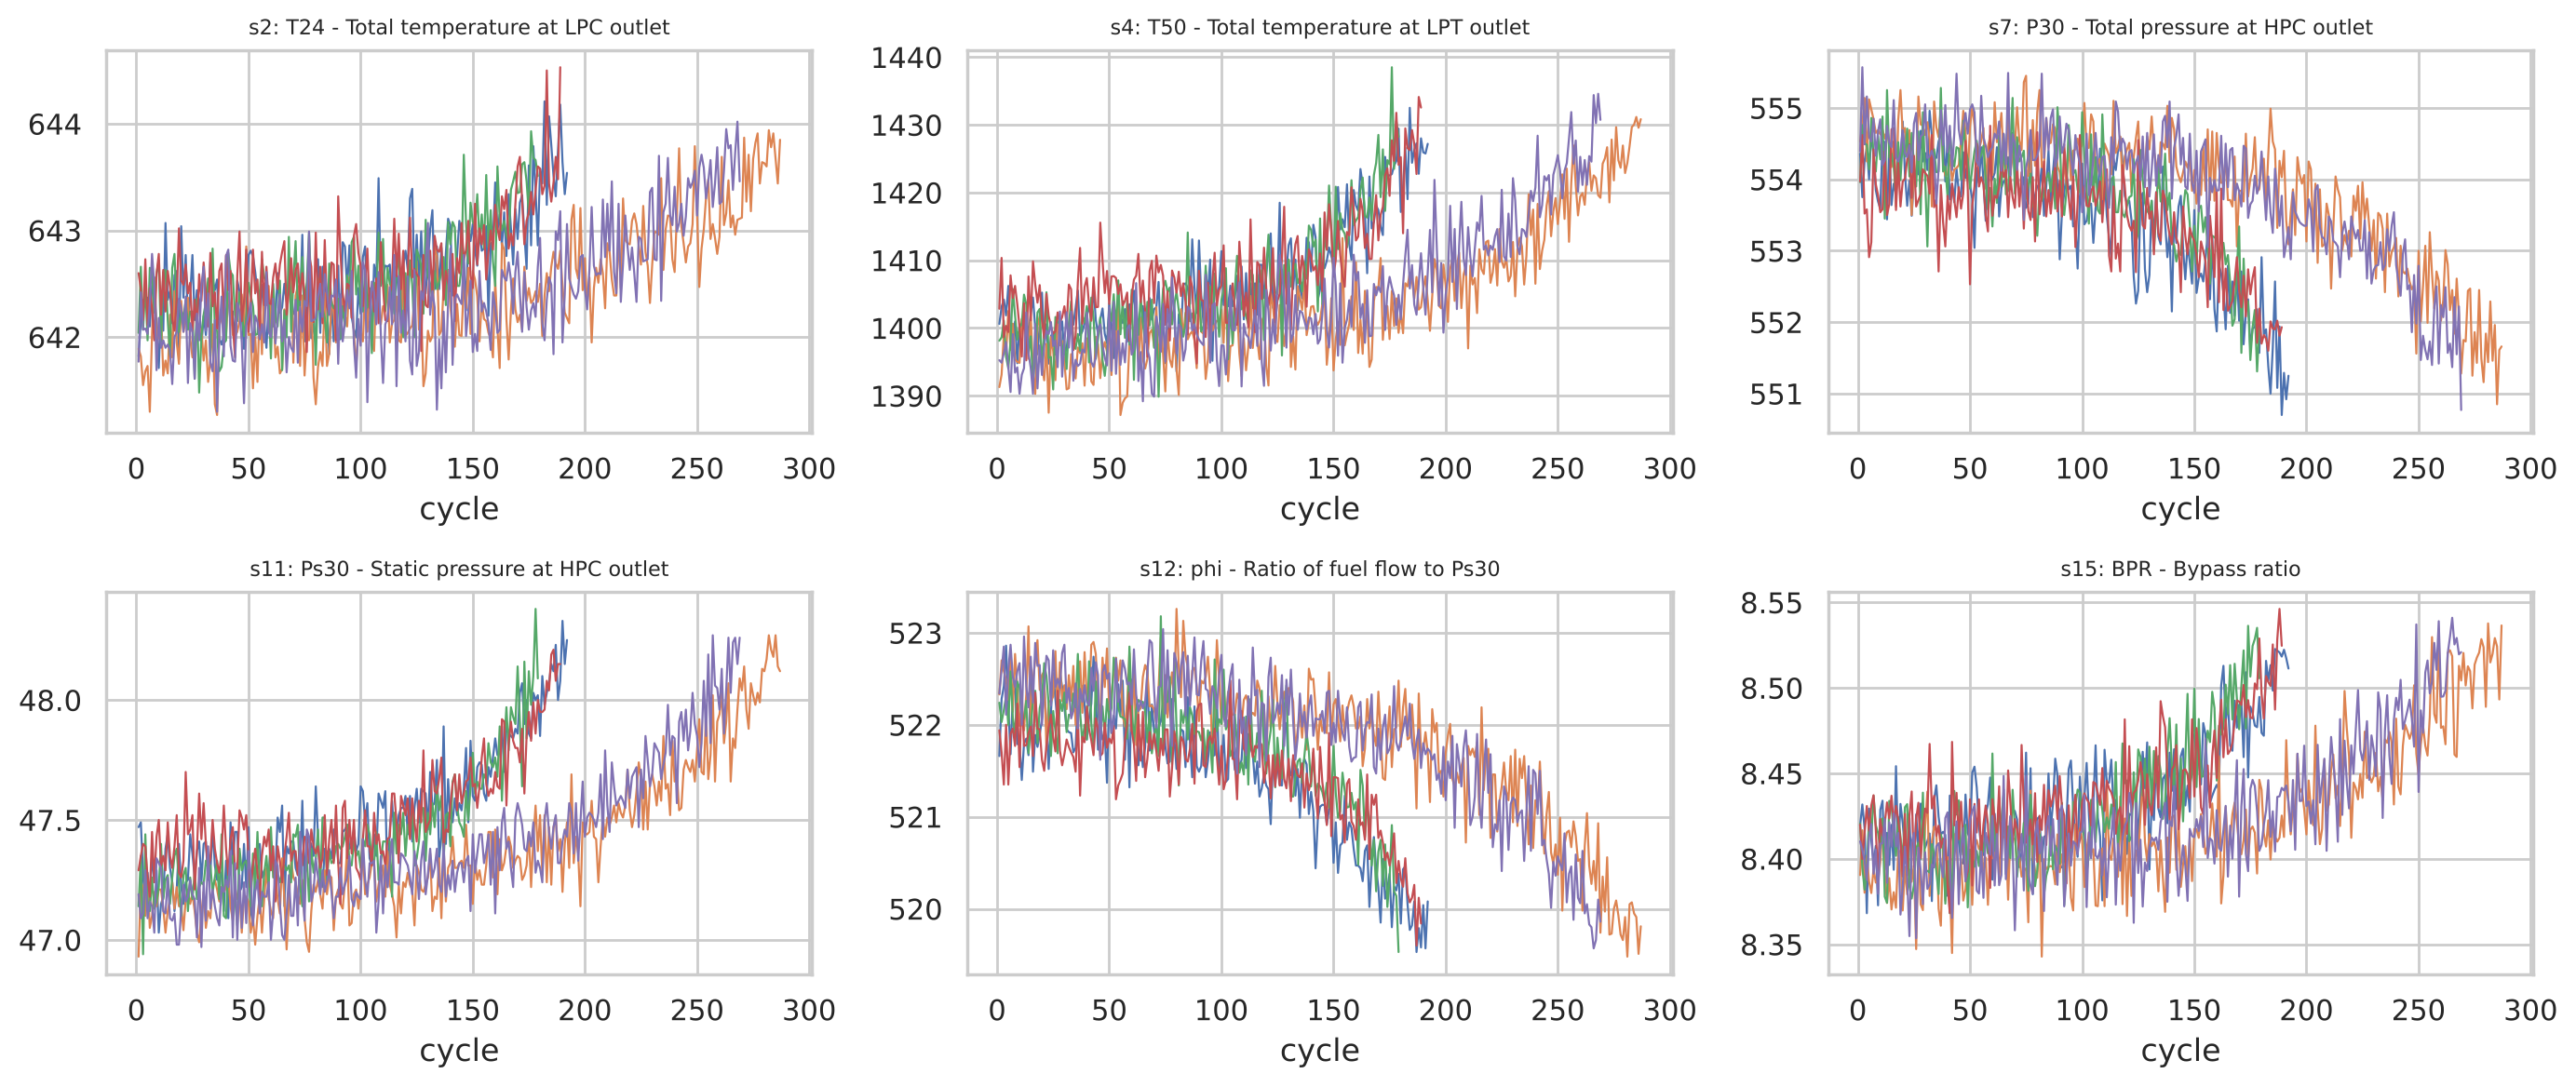

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, s in zip(ax.ravel(), ["s2", "s4", "s7", "s11", "s12", "s15"]):
    for u in [1, 2, 3, 4, 5]:
        g = train[train.unit == u]; a.plot(g.cycle, g[s], lw=.8)
    a.set_title(f"{s}: {cfg.SENSOR_DESCRIPTIONS[s]}", fontsize=8); a.set_xlabel("cycle")
plt.tight_layout(); plt.show()

Sensors drift up or down as the engine degrades. Different engines have different lifetimes (128 to 362 cycles in FD001).

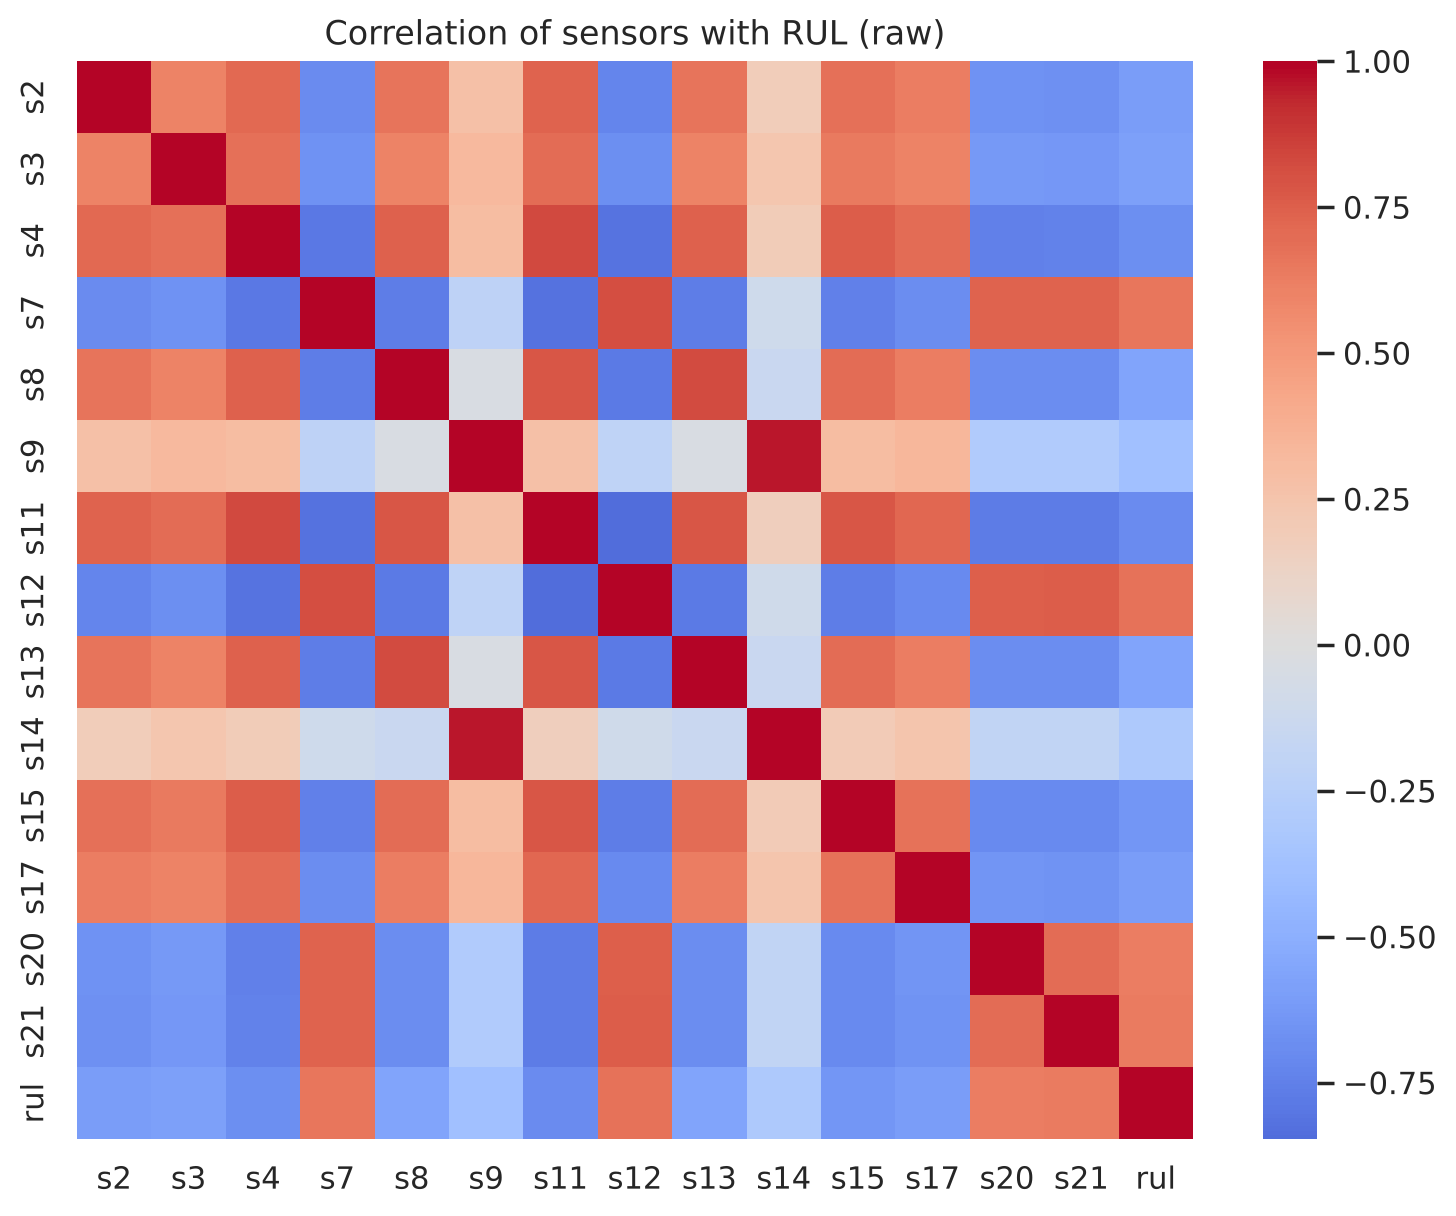

In [5]:
kept_raw = [s for s in cfg.SENSOR_COLS if train[s].nunique() > 2]
plt.figure(figsize=(9, 7))
sns.heatmap(train[kept_raw + ["rul"]].corr(), cmap="coolwarm", center=0)
plt.title("Correlation of sensors with RUL (raw)"); plt.show()

## 4. The target: RUL and the cap (Unit IV workflow)
For training rows `RUL = last cycle of the engine - current cycle`. Early in life an engine is simply "healthy", so we cap the target at **125** (a *piece-wise linear RUL*). This stops the model wasting effort on telling apart 300 vs 250 cycles left.

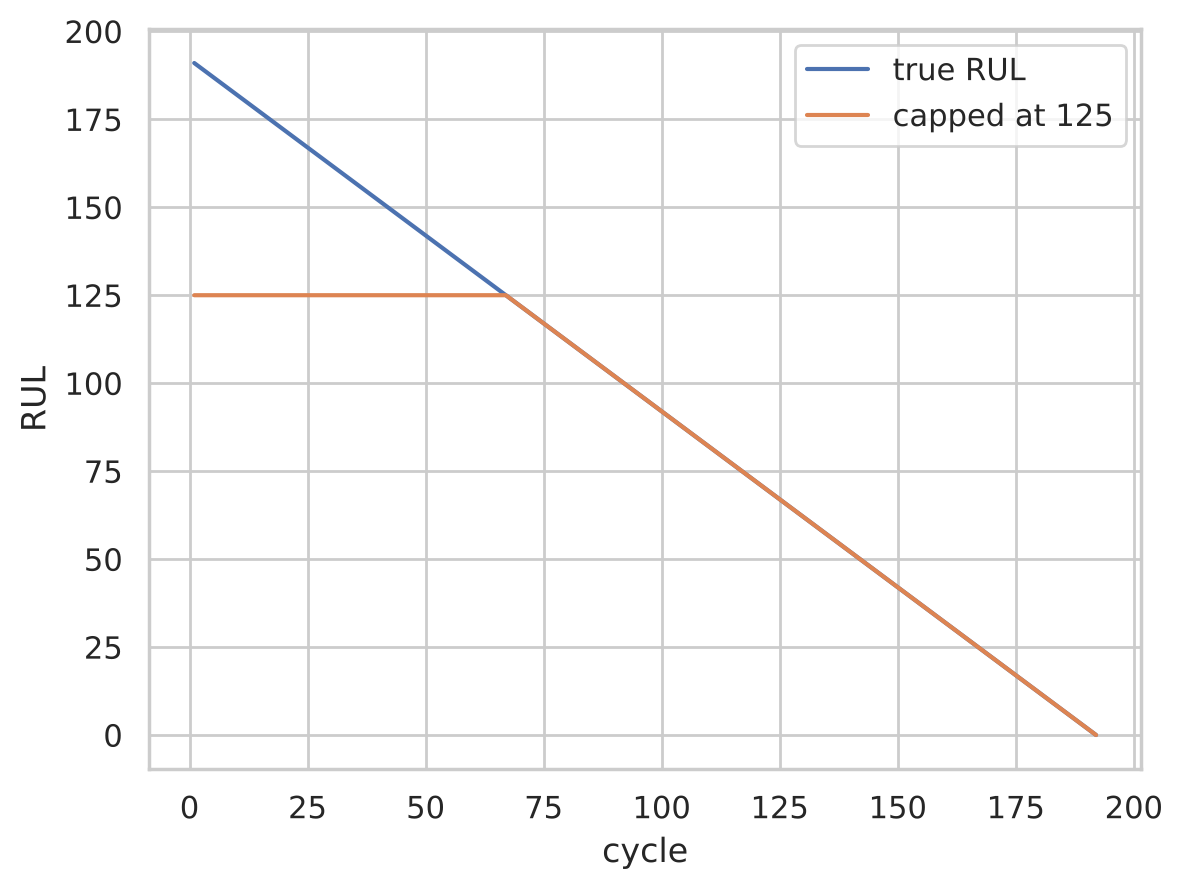

In [6]:
g = train[train.unit == 1]
plt.plot(g.cycle, g.rul, label="true RUL"); plt.plot(g.cycle, dl.cap_rul(g.rul), label=f"capped at {cfg.RUL_CAP}")
plt.xlabel("cycle"); plt.ylabel("RUL"); plt.legend(); plt.show()

## 5. Preprocessing: scaling and feature selection (Unit I)
The `Preprocessor` learns from **training engines only** (so no information leaks from validation/test):
1. find the operating condition (FD001 has one, FD002/FD004 have six),
2. drop constant sensors,
3. z-score scale each sensor,
4. drop sensors with almost no correlation to RUL.

In [7]:
pre = Preprocessor(cfg.SUBSETS[SUBSET]["conditions"]).fit(train, dl.cap_rul(train.rul))
pre.selection_report_.round(3)

,sensor,description,spearman_with_rul,status
0,s1,T2 - Total temperature at fan inlet,NaN,dropped: constant
1,s2,T24 - Total temperature at LPC outlet,-0.631,kept
2,s3,T30 - Total temperature at HPC outlet,-0.609,kept
3,s4,T50 - Total temperature at LPT outlet,-0.705,kept
4,s5,P2 - Pressure at fan inlet,NaN,dropped: constant
5,s6,P15 - Total pressure in bypass duct,NaN,dropped: constant
6,s7,P30 - Total pressure at HPC outlet,0.682,kept
7,s8,Nf - Physical fan speed,-0.573,kept
8,s9,Nc - Physical core speed,-0.327,kept
9,s10,epr - Engine pressure ratio,NaN,dropped: constant


## 6. Feature engineering (Unit I / Unit V)
For every kept sensor we build: the current value, a **rolling mean**, a **rolling standard deviation** and a **trend** over the last 10 cycles, plus the cycle number. Every feature only looks *backwards* in time, so a prediction never sees the future.

In [8]:
X = make_features(pre, train)
print(X.shape); X.iloc[:3, :9]

(20631, 57)


,cycle,s2,s2_mean10,s2_std10,s2_trend10,s3,s3_mean10,s3_std10,s3_trend10
0,1.0,-1.721684,-1.721684,0.000000,0.000000,-0.134252,-0.134252,0.000000,0.000000
1,2.0,-1.061754,-1.391719,0.466641,0.659930,0.211523,0.038636,0.244500,0.345775
2,3.0,-0.661797,-1.148411,0.535231,0.529944,-0.413156,-0.111961,0.312935,-0.139452


## 7. Split by engine, not by row (avoiding data leakage)
Neighbouring rows of one engine are almost identical. If we split rows randomly, the model would 'see' the validation engines during training and look better than it is. So we split by **engine id**.

In [9]:
from sklearn.model_selection import GroupShuffleSplit
tr_i, va_i = next(GroupShuffleSplit(1, test_size=cfg.VALIDATION_FRACTION, random_state=cfg.RANDOM_STATE).split(train, groups=train.unit))
tr, va = train.iloc[tr_i], train.iloc[va_i]
assert set(tr.unit).isdisjoint(va.unit)
print("train engines:", tr.unit.nunique(), "| validation engines:", va.unit.nunique())
pre_v = Preprocessor(1).fit(tr, dl.cap_rul(tr.rul))          # fitted on the 80 % only
Xtr, Xva = make_features(pre_v, tr), make_features(pre_v, va)
ytr, yva = dl.cap_rul(tr.rul).values, dl.cap_rul(va.rul).values

train engines: 80 | validation engines: 20


## 8. Train a few models live (Unit IV: regression) 
A quick comparison here; the full set of 13 models + baseline with tuning is run by `python run_pipeline.py` and shown in section 9.

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
models = {
 "Baseline (mean)": DummyRegressor(),
 "Ridge": make_pipeline(StandardScaler(), Ridge(10)),
 "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=0),
 "Random Forest (bagging)": RandomForestRegressor(60, max_depth=14, min_samples_leaf=5, max_features=.5, n_jobs=-1, random_state=0),
 "HistGradientBoosting (boosting)": HistGradientBoostingRegressor(max_iter=200, learning_rate=.08, random_state=0),
}
rows = []
for n, m in models.items():
    p = np.clip(m.fit(Xtr, ytr).predict(Xva), 0, cfg.RUL_CAP)
    rows.append({"model": n, **regression_metrics(yva, p)})
pd.DataFrame(rows).round(3)

,model,MAE,RMSE,R2
0,Baseline (mean),36.930,41.721,-0.000
1,Ridge,13.046,17.216,0.830
2,Decision Tree,11.449,17.186,0.830
3,Random Forest (bagging),9.914,14.858,0.873
4,HistGradientBoosting (boosting),10.113,15.236,0.867


**Metrics (regression):** `MAE` = average error in cycles; `RMSE` = like MAE but punishes big errors; `R²` = share of variance explained (1 = perfect, 0 = as bad as predicting the mean).
We do **not** use "accuracy" for regression - accuracy only makes sense for classification.

## 9. Full pipeline results (saved by `run_pipeline.py`)

In [11]:
val = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_regression_validation.csv")
val.round(3)

,model,family,tuned,MAE,RMSE,R2,fit_seconds
0,Random Forest (tuned),bagging,True,9.803,14.514,0.879,6.9
1,Gradient Boosting,boosting,False,10.226,14.776,0.875,22.3
2,Stacking (RF+HGB+Ridge),stacking,False,9.957,14.810,0.874,23.5
3,Random Forest,bagging,False,9.937,14.835,0.874,11.2
4,HistGradientBoosting (tuned),boosting,True,10.070,14.924,0.872,1.5
5,Bagging (Decision Trees),bagging,False,10.028,14.992,0.871,6.2
6,SVR (RBF) (tuned),kernel,True,10.657,15.149,0.868,2.1
7,SVR (RBF),kernel,False,10.944,15.414,0.863,2.7
8,HistGradientBoosting,boosting,False,10.235,15.441,0.863,1.1
9,AdaBoost,boosting,False,12.945,16.195,0.849,16.0


**Hyper-parameter tuning (Unit III)** - GridSearchCV and RandomizedSearchCV with GroupKFold, so folds never split an engine.

In [12]:
pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_tuning.csv")

,model,method,best_params,cv_rmse_train_engines,val_rmse_default,val_rmse_tuned,search_seconds
0,Ridge,GridSearchCV,"{""model__alpha"": 1000}",20.690,17.216,17.329,0.3
1,Decision Tree,GridSearchCV,"{""max_depth"": 6, ""min_samples_leaf"": 50}",18.563,17.168,16.574,11.5
2,SVR (RBF),GridSearchCV,"{""estimator__model__C"": 50, ""estimator__model_...",18.140,15.414,15.149,101.5
3,HistGradientBoosting,RandomizedSearchCV,"{""min_samples_leaf"": 20, ""max_leaf_nodes"": 15,...",16.941,15.441,14.924,40.5
4,Random Forest,RandomizedSearchCV,"{""min_samples_leaf"": 5, ""max_features"": 0.3, ""...",16.876,14.835,14.514,35.7


**Final test (official NASA protocol):** models are re-fitted on all training engines and scored once on the last cycle of every test engine against `RUL_FD001.txt`. The *NASA score* penalises late predictions (over-estimating RUL) more than early ones.

In [13]:
test_tbl = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_regression_test.csv")
test_tbl[["model", "family", "official_MAE", "official_RMSE", "official_R2", "official_NASA_score", "all_cycles_RMSE"]].round(2)

,model,family,official_MAE,official_RMSE,official_R2,official_NASA_score,all_cycles_RMSE
0,Gradient Boosting,boosting,12.89,17.98,0.81,696.59,15.53
1,HistGradientBoosting (tuned),boosting,13.73,18.60,0.80,698.75,15.80
2,Random Forest (tuned),bagging,13.53,18.63,0.80,667.74,15.89
3,Stacking (RF+HGB+Ridge),stacking,13.81,18.75,0.80,768.54,15.86
4,Random Forest,bagging,13.82,18.80,0.80,700.66,16.12
5,HistGradientBoosting,boosting,13.88,19.19,0.79,810.31,16.26
6,Bagging (Decision Trees),bagging,14.30,19.25,0.79,730.55,16.25
7,SVR (RBF) (tuned),kernel,13.63,19.32,0.78,995.71,16.15
8,Decision Tree (tuned),tree,14.68,19.62,0.78,716.99,17.04
9,AdaBoost,boosting,14.96,19.62,0.78,633.44,18.23


## 10. RUL prediction curves vs ground truth (deliverable)

Best model (chosen on validation): Random Forest (tuned)


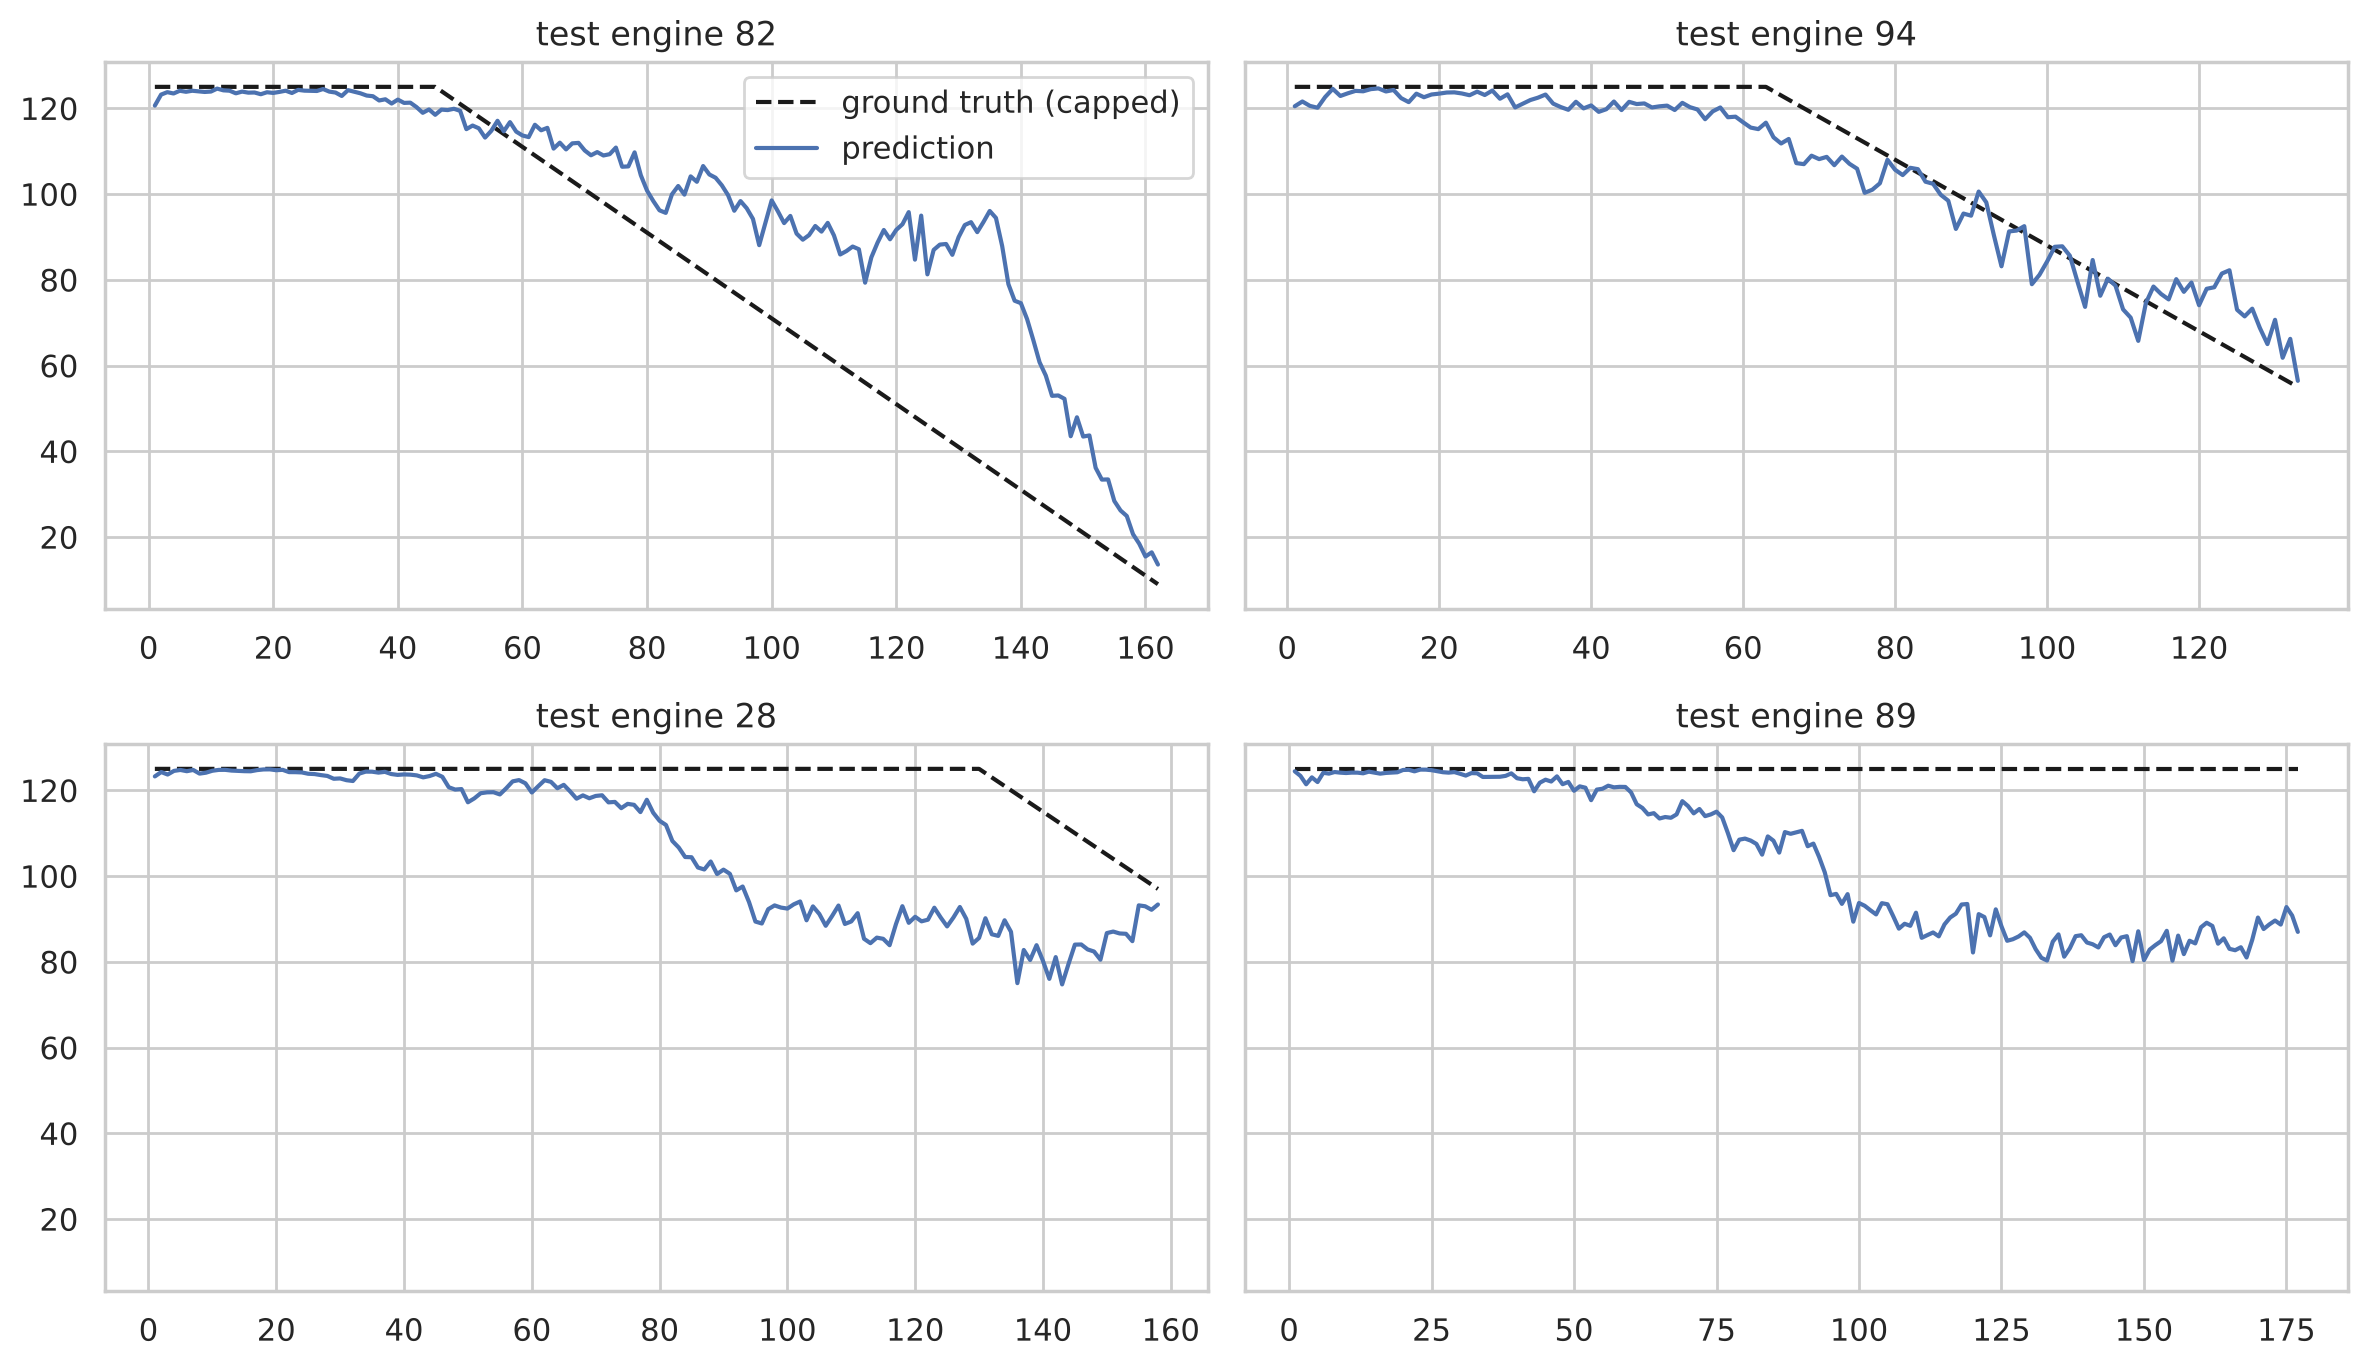

In [14]:
summ = json.loads((cfg.METRICS_DIR / f"{SUBSET}_summary.json").read_text())
best = summ["best_model"]; print("Best model (chosen on validation):", best)
te = pd.read_csv(cfg.PREDICTIONS_DIR / f"{SUBSET}_test_predictions.csv.gz")
from src.visualization import pick_engines
last = te[te.is_last_cycle].set_index("unit")["rul_true"]
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for a, u in zip(ax.ravel(), pick_engines(last)):
    g = te[te.unit == u]
    a.plot(g.cycle, np.minimum(g.rul_true, cfg.RUL_CAP), "k--", label="ground truth (capped)")
    a.plot(g.cycle, g[f"pred::{best}"], label="prediction"); a.set_title(f"test engine {u}")
ax[0, 0].legend(); plt.tight_layout(); plt.show()

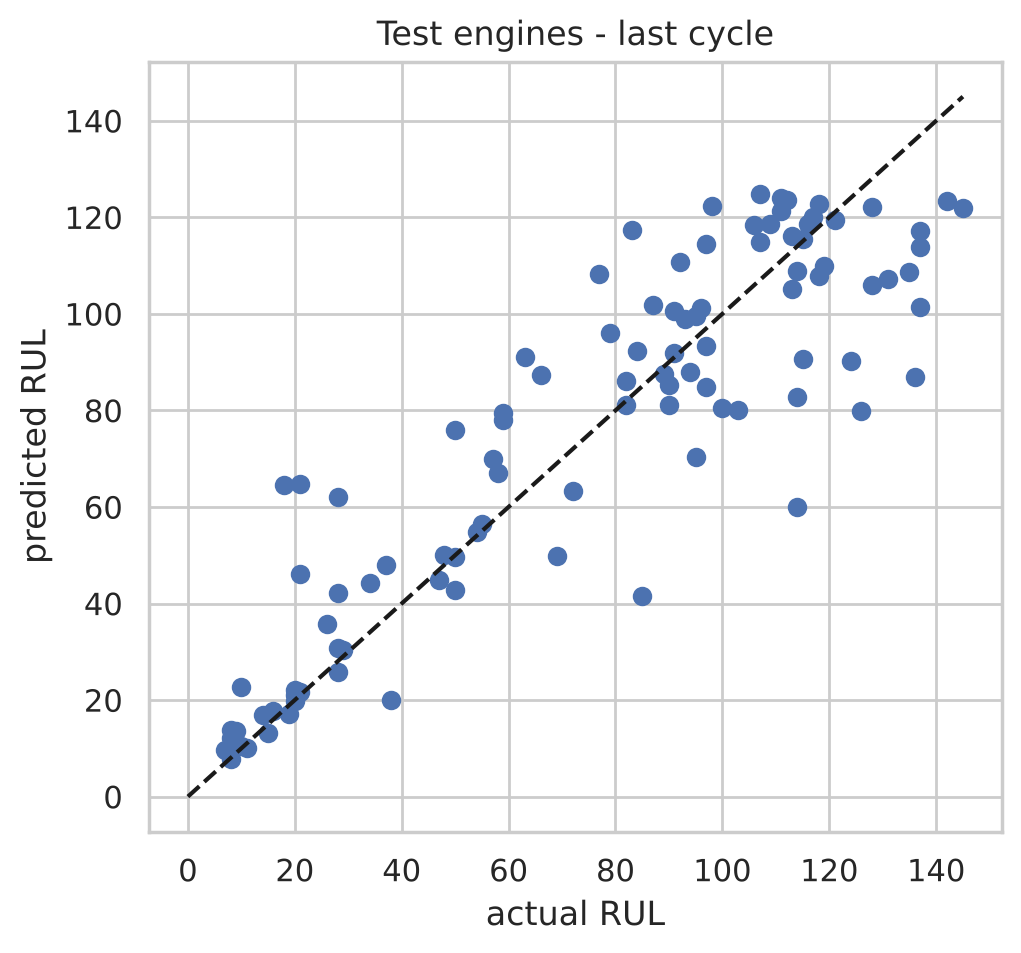

In [15]:
l = te[te.is_last_cycle]
plt.figure(figsize=(5.5, 5)); plt.scatter(l.rul_true, l[f"pred::{best}"]); m = max(l.rul_true.max(), 125)
plt.plot([0, m], [0, m], "k--"); plt.xlabel("actual RUL"); plt.ylabel("predicted RUL"); plt.title("Test engines - last cycle"); plt.show()

## 11. Ensembles (Unit III)
A single tree is unstable. **Bagging** (Bagging, Random Forest) averages many trees trained on different samples -> lower variance. **Boosting** (AdaBoost, Gradient Boosting, HistGB) builds trees one after another, each fixing the previous errors -> lower bias. **Stacking** feeds several models' predictions into a final model.

In [16]:
val.groupby("family")["RMSE"].min().sort_values().round(2)

family
bagging     14.51
boosting    14.78
stacking    14.81
kernel      15.15
tree        16.57
linear      17.00
baseline    41.72
Name: RMSE, dtype: float64

## 12. Fault-risk classification (Unit II)
Target: **RUL <= 30 cycles** = 'imminent fault'. This class is rare, so models use `class_weight='balanced'`.

In [17]:
cv = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_classification_validation.csv")
cv[["model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].round(3)

,model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVM (RBF),0.962,0.845,0.916,0.879,0.990
1,K-Nearest Neighbors,0.961,0.900,0.840,0.869,0.987
2,HistGradientBoosting,0.955,0.820,0.905,0.860,0.990
3,Logistic Regression,0.941,0.738,0.948,0.830,0.990
4,Random Forest,0.941,0.752,0.913,0.824,0.989
5,Naive Bayes,0.924,0.674,0.976,0.797,0.987
6,Perceptron,0.929,0.713,0.897,0.794,0.978
7,Decision Tree,0.916,0.656,0.945,0.775,0.966


In [18]:
ct = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_classification_test.csv")
ct[ct.evaluation == "all test cycles"][["model", "n", "positives", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "TN", "FP", "FN", "TP"]].round(3)

,model,n,positives,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,Perceptron,13096,332,0.968,0.430,0.867,0.575,0.987,12383,381,44,288
2,Logistic Regression,13096,332,0.980,0.577,0.831,0.681,0.989,12562,202,56,276
4,K-Nearest Neighbors,13096,332,0.986,0.811,0.581,0.677,0.962,12719,45,139,193
6,Decision Tree,13096,332,0.976,0.524,0.804,0.634,0.915,12521,243,65,267
8,SVM (RBF),13096,332,0.985,0.695,0.741,0.717,0.985,12656,108,86,246
10,Naive Bayes,13096,332,0.976,0.512,0.864,0.643,0.991,12490,274,45,287
12,Random Forest,13096,332,0.983,0.642,0.762,0.697,0.989,12623,141,79,253
14,HistGradientBoosting,13096,332,0.985,0.702,0.717,0.709,0.989,12663,101,94,238


*Precision* = of the alarms raised, how many were real. *Recall* = of the real near-failure cycles, how many we caught. *F1* balances both. *ROC-AUC* measures ranking quality independent of the threshold. The **confusion matrix** counts TN/FP/FN/TP.

## 13. Explainable AI (Unit III)
**Global** importance = what matters on average. **Local** = why one particular prediction was made. SHAP values are in *cycles*: positive pushes RUL up, negative pushes it down.

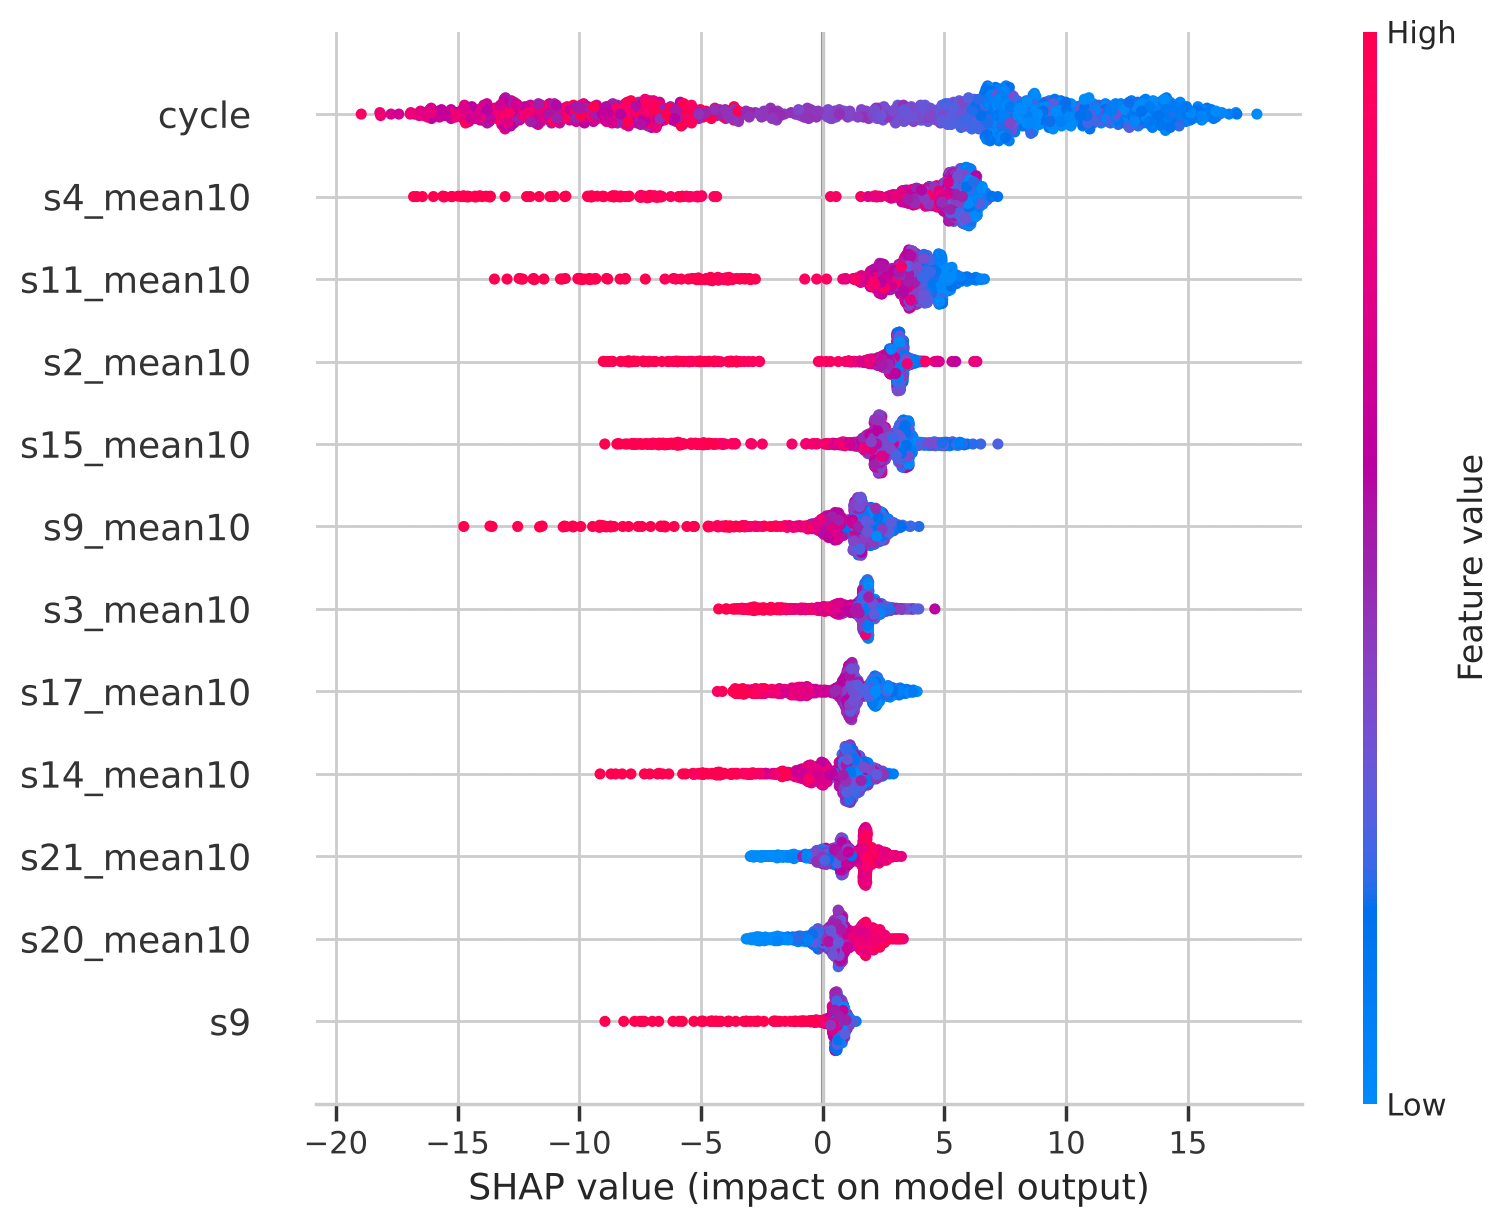

In [19]:
import shap
s = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_shap_sample.csv.gz")
vals = s[[c for c in s.columns if c.startswith("shap::")]]; feats = s[[c for c in s.columns if c.startswith("val::")]]
vals.columns = [c[6:] for c in vals.columns]; feats.columns = [c[5:] for c in feats.columns]
shap.summary_plot(vals.values, feats, max_display=12)

The same explanations are available interactively in the website (**Explainable AI** page), including LIME for one engine at one cycle.

## 14. Time series (Unit V)

In [20]:
ts = json.loads((cfg.METRICS_DIR / f"{SUBSET}_timeseries.json").read_text())
print("Sensor:", ts["sensor"], ts["sensor_description"], "| engine", ts["engine"])
print("ADF p-value raw:", round(ts["adf_pvalue_raw"], 4), "| after 1st difference:", ts["adf_pvalue_condition_normalised_first_difference"])
print("Seasonality check:", ts["seasonality_check"])
pd.Series(ts["forecast_rmse_normalised_units"]).round(3).rename("hold-out RMSE")

Sensor: s11 Ps30 - Static pressure at HPC outlet | engine 26
ADF p-value raw: 0.9989 | after 1st difference: 3.3273586663507554e-14
Seasonality check: {'strongest_lag_in_differenced_series': 22, 'abs_acf_at_that_lag': 0.2303904938228921, '95pct_band': 0.15592922769844308, 'seasonal_pattern_present': False}


Naive (last value)         1.309
Moving average (10)        0.936
AR(2) + trend              0.845
MA(2) + trend              0.849
ARIMA(1,1,1) + drift       0.809
SARIMA(1,1,1)(1,0,1,22)    0.835
Name: hold-out RMSE, dtype: float64

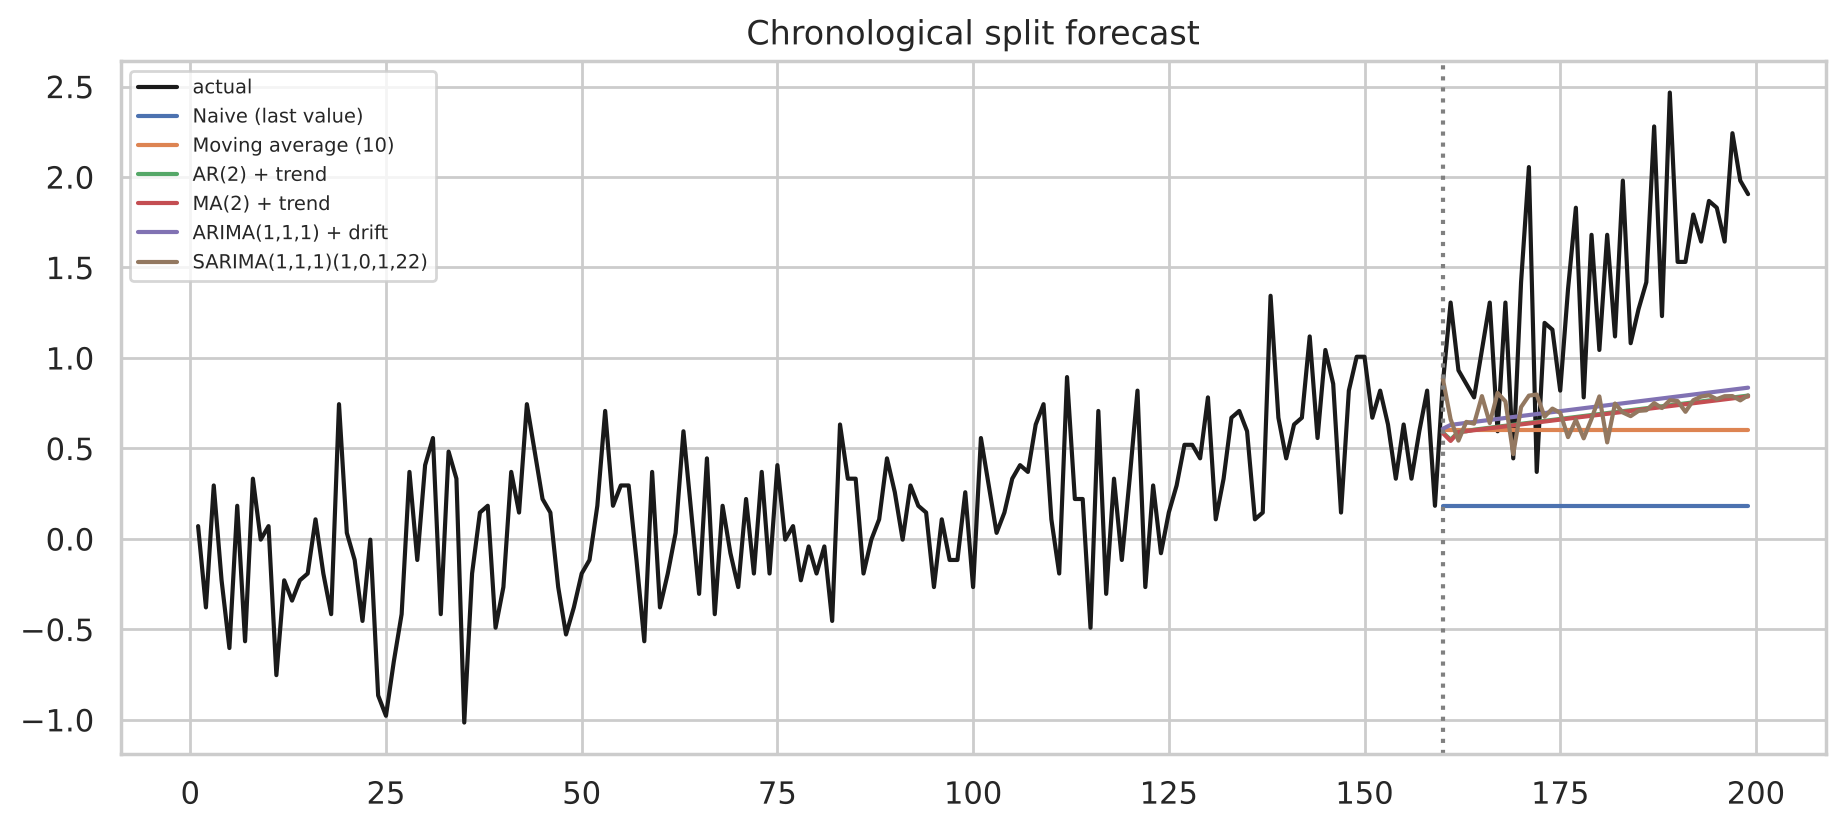

{
 "failure_level_health_indicator": 1.7285265534945848,
 "arima_health_indicator": {
  "MAE": 28.63,
  "RMSE": 35.142709058921454,
  "R2": 0.2848272967455098,
  "NASA_score": 15961.327056644823
 },
 "supervised_best_model": {
  "name": "Random Forest (tuned)",
  "MAE": 13.534959171540867,
  "RMSE": 18.63104615471079,
  "R2": 0.7989912609388898,
  "NASA_score": 667.7444556808745
 }
}


In [21]:
fc = pd.read_csv(cfg.METRICS_DIR / f"{SUBSET}_ts_forecast.csv")
plt.figure(figsize=(11, 4.5)); plt.plot(fc.cycle, fc.actual, "k", label="actual")
for c in [c for c in fc.columns if c not in ("cycle", "actual", "split")]: plt.plot(fc.cycle, fc[c], label=c)
plt.axvline(fc[fc.split == "holdout"].cycle.min(), color="gray", ls=":"); plt.legend(fontsize=7); plt.title("Chronological split forecast"); plt.show()
print(json.dumps(ts["rul_baseline_comparison"], indent=1))

**Take-aways.** The sensor is *non-stationary* (it trends). AR/MA/ARIMA can extrapolate a single series, but a fleet-level supervised model that also uses the other sensors and learns from many engines is better for RUL. SARIMA needs a repeating seasonal pattern - there is none here, so it brings no benefit.

## 15. Run the website
```
streamlit run app.py
```